### 5. Кривая отдачи: где заканчивается польза?

Растёт ли количество баллов за экзамен линейно с количеством часов учебы за день, или есть точка насыщения, после которой дополнительные часы учёбы дают всё меньше? Если да — где она? И как количество часов учебы влияет на ментальное здоровье? 

In [1]:
import sys
import os
from pathlib import Path

project_root = Path(os.getcwd()).parent 
sys.path.insert(0, str(project_root))

from src.preparation import load_df
df = load_df()

,,students_qty,avg_exam_score,avg_mental_health
study_hours_group,age_group,,,
0-1,17-20,23,40.2,6.1
1-2,17-20,48,50.0,5.5
2-3,17-20,105,60.7,5.2
3-4,17-20,151,70.1,5.7
4-5,17-20,109,79.0,5.5
5-6,17-20,54,89.1,6.3
6-7,17-20,12,97.4,5.7
7-9,17-20,7,99.7,5.7
0-1,21-24,21,39.9,5.2


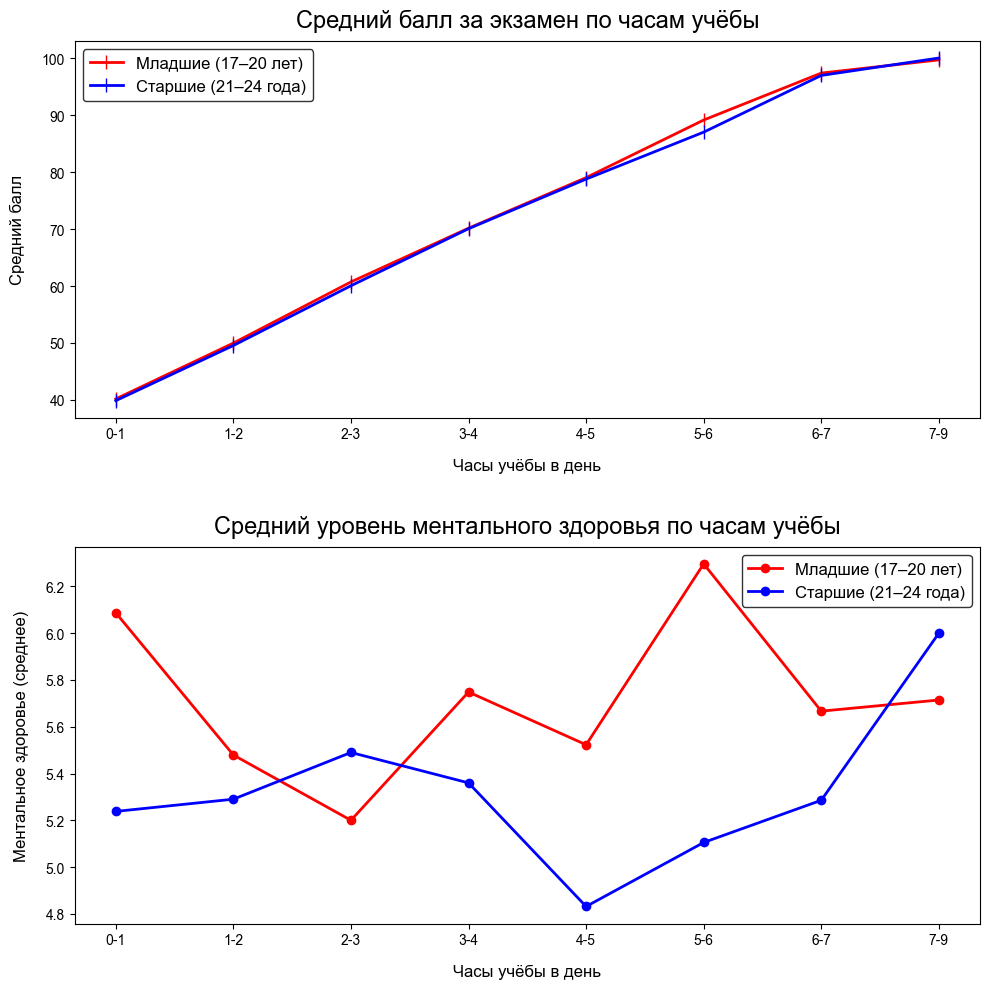

In [2]:
import pandas as pd 
import matplotlib.pyplot as plt 
import src.constants as cnst 
from itertools import pairwise

plt.rcParams['font.family'] = 'Arial'

df_02_05 = df.copy()

bins = [0, 1, 2, 3, 4, 5, 6, 7, 9]  

df_02_05['study_hours_group'] = pd.cut(
    df_02_05.study_hours_per_day, 
    bins=bins, 
    include_lowest=True, 
    labels=[f'{t[0]}-{t[1]}' for t in pairwise(bins)]
    )

df_02_05['age_group'] = df_02_05.age.apply(lambda a: '17-20' if a <= 20 else '21-24')

res_02_05 = df_02_05.groupby(['study_hours_group', 'age_group']).agg(
    students_qty=('student_id', 'count'), 
    avg_exam_score=('exam_score', 'mean'), 
    avg_mental_health=('mental_health_rating', 'mean'),
).sort_index(level=1)

sbs = ['avg_exam_score', 'avg_mental_health']
display(res_02_05.style.format('{:.1f}', subset=sbs).background_gradient(subset=sbs, cmap='Blues'))


res_02_05_young = res_02_05.filter(like='17-20', axis=0).droplevel(1)
res_02_05_adult = res_02_05.filter(like='21-24', axis=0).droplevel(1)

fig, (ax1, ax2) = plt.subplots(2, figsize=(10, 10))
    
ax1.plot(
    res_02_05_young.index, res_02_05_young.avg_exam_score, 
    color='red', lw=2, marker='|', ms=10,
    label=cnst.YOUNG_LABEL
)
ax1.plot(
    res_02_05_adult.index, res_02_05_adult.avg_exam_score, 
    color='blue', lw=2, marker='|', ms=10,
    label=cnst.ADULT_LABEL
)

ax2.plot(
    res_02_05_young.index, res_02_05_young.avg_mental_health, 
     color='red', lw=2, marker='o',
     label=cnst.YOUNG_LABEL
)
ax2.plot(
    res_02_05_adult.index, res_02_05_adult.avg_mental_health, 
     color='blue', lw=2, marker='o',
     label=cnst.ADULT_LABEL
)

ax1.legend(**cnst.LEGEND_PARAMS)
ax2.legend(**cnst.LEGEND_PARAMS)

ax1.set_title('Средний балл за экзамен по часам учёбы', **cnst.TITLE_PARAMS)
ax1.set_xlabel('Часы учёбы в день', **cnst.LABEL_PARAMS)
ax1.set_ylabel('Средний балл', **cnst.LABEL_PARAMS)

ax2.set_title('Средний уровень ментального здоровья по часам учёбы', **cnst.TITLE_PARAMS)
ax2.set_xlabel('Часы учёбы в день', **cnst.LABEL_PARAMS)
ax2.set_ylabel('Ментальное здоровье (среднее)', **cnst.LABEL_PARAMS)

plt.tight_layout(h_pad=3)

#### 06. Выводы

**1. Оценка за экзамен растёт линейно до 6 часов.** Средний балл увеличивается с 40.2 до 97.4 у младших и с 39.9 до 96.9 у старших при росте учёбы с 0–1 до 6–7 часов. Далее прирост ограничен верхней границей шкалы (100 баллов). В группе 7–9 часов средний балл составляет 99.7 и 100.0 — студенты достигли потолка. Это не позволяет определить точку насыщения в привычном смысле: дальнейший рост невозможен из-за ограничения шкалы, а не из-за реального снижения отдачи.

**2. Возраст не влияет на связь количества учёбы и оценки за экзамен.** Кривые exam_score для 17–20 и 21–24 лет практически совпадают во всех группах: разница составляет менее 1.5 балла и находится в пределах случайной вариации.

**3. Ментальное здоровье показывает разную динамику по возрастам.** У младшей группы (17–20) уровень ментального здоровья нестабилен, но в среднем выше. Пик — на 5–6 часах учебы (6.3). У старших (21–24) наблюдается провал на 4–5 часах (4.8) и низкое значение на 5–6 (5.1). Это указывает на связь между возрастом и эффектом учёбы на ментальное здоровье. Так, учеба связана с более низким уровнем ментального здоровья у старшей группы. Возможное объяснение — более высокая занятость старшей группы (работа на полную ставку, написание диплома), однако в датасете нет данных для проверки этой гипотезы.

**Ограничения.** Группы 6–7 и 7–9 часов малочисленны (n < 25), что снижает надёжность выводов по этим интервалам. Порог возраста (20 лет) — произвольный; при его сдвиге результаты могут измениться.